# 🍽️ Food Delivery EDA — India Restaurant Dataset

**Author:** DEVAM SHAH    
**Dataset:** Food Delivery Dataset (211,944 rows × 26 columns)

---

## 📌 Project Overview

This project performs a comprehensive **Exploratory Data Analysis (EDA)** on a large food delivery dataset containing restaurant information across multiple cities in India.  
The goal is to uncover patterns in **ratings, pricing, delivery availability, cuisine types, and regional distribution** to derive actionable business insights.

---

## 📋 Table of Contents

1. [Import Libraries & Set Options](#1-importing-libraries)
2. [Reading Data](#2-reading-data)
3. [Understand & Prepare Data](#3-understand-and-prepare-data)
4. [Understanding the Variables (EDA Basics)](#4-understanding-the-variables)
5. [Checking for Missing Values & Duplicates](#5-checking-for-missing-values)
6. [Feature Engineering — `region` Variable](#6-feature-engineering)
7. [Study Correlation & Detect Outliers](#7-correlation-and-outliers)
8. [Key Business Insights](#8-key-business-insights)
9. [Extra Insights — City & Cuisine Analysis](#9-extra-insights)

---

## 🛠️ Tools & Libraries Used

| Library | Purpose |
|---|---|
| `pandas` | Data manipulation and analysis |
| `numpy` | Numerical operations |
| `matplotlib` | Data visualization |
| `seaborn` | Advanced statistical visualizations |

---

## 🔍 Key Findings (TL;DR)

- **Higher price ≠ Higher rating** — Cost and ratings are not strongly correlated.
- **Photos drive votes** — More restaurant photos correlate with more user votes.
- **Delivery is a gap** — Most restaurants do NOT offer delivery (first-mover opportunity).
- **Northeast region** leads in restaurant density and cuisine variety.
- **Price Range 3** offers the best rating-to-cost ratio across restaurants.


---
> **Workflow:** Import → Read → Clean → EDA → Correlations → Insights

## 1. Importing Libraries

In [7]:
# Importing libraries needed for the project

import pandas as pd # For data manipulation and analysis
import numpy as np # For numerical operations and array handling
import matplotlib.pyplot as plt # For data visualization
import seaborn as sns # For advanced data visualization if needed

# Will add other libraries as needed during the project - Might add geopy and datetime libraries later if required

## 2. Setting Display Options

In [8]:
# Setting options to view all columns of the dataframe and to view 50 rows of the dataframe

pd.set_option('display.max_columns', None)  # Displays all columns in the DataFrame
pd.set_option('display.max_rows', 50)     # Displays up to 50 rows in the DataFrame

## 3. Reading Data

In [9]:
# Loading the dataset / Reading the dataset

food_dely = pd.read_csv('food_dely.csv')

In [10]:
# Displaying the first 5 rows of the dataset to understand its structure
# Inspecting the dataset and understanding it.

food_dely.head(5)

,res_id,name,establishment,url,address,city,city_id,locality,latitude,longitude,zipcode,country_id,locality_verbose,cuisines,timings,average_cost_for_two,price_range,currency,highlights,aggregate_rating,rating_text,votes,photo_count,opentable_support,delivery,takeaway
0,3400299,Bikanervala,Quick Bites,https://www.zomato.com/agra/bikanervala-khanda...,"Kalyani Point, Near Tulsi Cinema, Bypass Road,...",Agra,34,Khandari,27.211450,78.002381,NaN,1,"Khandari, Agra","North Indian, South Indian, Mithai, Street Foo...",8:30am – 10:30pm (Mon-Sun),700,2,Rs.,"Lunch, Takeaway Available, Credit Card, Dinner...",4.4,Very Good,814,154,0.0,-1,-1
1,3400005,Mama Chicken Mama Franky House,Quick Bites,https://www.zomato.com/agra/mama-chicken-mama-...,"Main Market, Sadar Bazaar, Agra Cantt, Agra",Agra,34,Agra Cantt,27.160569,78.011583,282001,1,"Agra Cantt, Agra","North Indian, Mughlai, Rolls, Chinese, Fast Fo...","12:30PM to 12Midnight (Mon, Wed, Thu, Fri, Sat...",600,2,Rs.,"Delivery, No Alcohol Available, Dinner, Takeaw...",4.4,Very Good,1203,161,0.0,-1,-1
2,3401013,Bhagat Halwai,Quick Bites,https://www.zomato.com/agra/bhagat-halwai-2-sh...,"62/1, Near Easy Day, West Shivaji Nagar, Goalp...",Agra,34,Shahganj,27.182938,77.979684,282010,1,"Shahganj, Agra","Fast Food, Mithai",9:30 AM to 11 PM,300,1,Rs.,"No Alcohol Available, Dinner, Takeaway Availab...",4.2,Very Good,801,107,0.0,1,-1
3,3400290,Bhagat Halwai,Quick Bites,https://www.zomato.com/agra/bhagat-halwai-civi...,"Near Anjana Cinema, Nehru Nagar, Civil Lines, ...",Agra,34,Civil Lines,27.205668,78.004799,282002,1,"Civil Lines, Agra","Desserts, Bakery, Fast Food, South Indian",8am – 11pm (Mon-Sun),300,1,Rs.,"Takeaway Available, Credit Card, Lunch, Delive...",4.3,Very Good,693,157,0.0,1,-1
4,3401744,The Salt Cafe Kitchen & Bar,Casual Dining,https://www.zomato.com/agra/the-salt-cafe-kitc...,"1C,3rd Floor, Fatehabad Road, Tajganj, Agra",Agra,34,Tajganj,27.157709,78.052421,NaN,1,"Tajganj, Agra","North Indian, Continental, Italian",11:30 AM to 11:30 PM,1000,3,Rs.,"Lunch, Serves Alcohol, Cash, Credit Card, Dinn...",4.9,Excellent,470,291,0.0,1,-1


In [11]:
# Displaying the last 5 rows of the dataset to check for any inconsistencies at the end
# Inspecting the dataset and understanding it.
food_dely.tail(5)

,res_id,name,establishment,url,address,city,city_id,locality,latitude,longitude,zipcode,country_id,locality_verbose,cuisines,timings,average_cost_for_two,price_range,currency,highlights,aggregate_rating,rating_text,votes,photo_count,opentable_support,delivery,takeaway
211939,3202251,Kali Mirch Cafe And Restaurant,Casual Dining,https://www.zomato.com/vadodara/kali-mirch-caf...,"Manu Smriti Complex, Near Navrachna School, GI...",Vadodara,32,Fatehgunj,22.336931,73.192356,390024,1,"Fatehgunj, Vadodara",North Indian,"11am – 3pm, 7pm – 11:30pm (Mon-Sun)",600,2,Rs.,"Dinner, Cash, Lunch, Delivery, Indoor Seating,...",4.1,Very Good,243,40,0.0,-1,-1
211940,3200996,Raju Omlet,Quick Bites,https://www.zomato.com/vadodara/raju-omlet-kar...,"Mahalaxmi Apartment, Opposite B O B, Karoli Ba...",Vadodara,32,Karelibaug,22.322455,73.197203,NaN,1,"Karelibaug, Vadodara",Fast Food,"4pm – 11pm (Mon, Tue, Wed, Fri, Sat, Sun), 4pm...",300,1,Rs.,"Dinner, Cash, Takeaway Available, Debit Card, ...",4.1,Very Good,187,40,0.0,1,-1
211941,18984164,The Grand Thakar,Casual Dining,https://www.zomato.com/vadodara/the-grand-thak...,"3rd Floor, Shreem Shalini Mall, Opposite Conqu...",Vadodara,32,Alkapuri,22.310563,73.171164,NaN,1,"Alkapuri, Vadodara","Gujarati, North Indian, Chinese","11:30 AM to 3:30 PM, 7:30 PM to 11 PM",700,2,Rs.,"Dinner, Cash, Debit Card, Lunch, Takeaway Avai...",4.0,Very Good,111,38,0.0,-1,-1
211942,3201138,Subway,Quick Bites,https://www.zomato.com/vadodara/subway-1-akota...,"G-2, Vedant Platina, Near Cosmos, Akota, Vadodara",Vadodara,32,Akota,22.270027,73.143068,NaN,1,"Akota, Vadodara","Fast Food, Sandwich, Salad",8 AM to 1 AM,500,2,Rs.,"Dinner, Delivery, Credit Card, Lunch, Cash, Ta...",3.7,Good,128,34,0.0,1,-1
211943,18879846,Freshcos - The Health Cafe,Café,https://www.zomato.com/vadodara/freshcos-the-h...,"Shop 7, Ground Floor, Opposite Natubhai Circle...",Vadodara,32,Vadiwadi,22.309935,73.158768,390007,1,"Vadiwadi, Vadodara","Cafe, Healthy Food, Coffee",7am – 11pm (Mon-Sun),600,2,Rs.,"Dinner, Cash, Takeaway Available, Debit Card, ...",4.0,Very Good,93,53,0.0,1,-1


## Performing EDA(Exploratory Data Analysis)

In [12]:
# Describing the dataset to get statistical summary of numerical columns
# Understanding the numerical columns in the dataset
food_dely.describe()

,res_id,city_id,latitude,longitude,country_id,average_cost_for_two,price_range,aggregate_rating,votes,photo_count,opentable_support,delivery,takeaway
count,2.119440e+05,211944.000000,211944.000000,211944.000000,211944.0,211944.000000,211944.000000,211944.000000,211944.000000,211944.000000,211896.0,211944.000000,211944.0
mean,1.349411e+07,4746.785434,21.499475,77.615276,1.0,595.812229,1.882535,3.395937,378.002571,256.971224,0.0,-0.255907,-1.0
std,7.883722e+06,5568.766386,22.781261,7.500104,0.0,606.239363,0.892989,1.283642,925.333106,867.668940,0.0,0.964172,0.0
min,5.000000e+01,1.000000,0.000000,0.000000,1.0,0.000000,1.000000,0.000000,0.000000,0.000000,0.0,-1.000000,-1.0
25%,3.301027e+06,11.000000,15.496071,74.877961,1.0,250.000000,1.000000,3.300000,16.000000,3.000000,0.0,-1.000000,-1.0
50%,1.869573e+07,34.000000,22.514181,77.425971,1.0,400.000000,2.000000,3.800000,100.000000,18.000000,0.0,-1.000000,-1.0
75%,1.881297e+07,11306.000000,26.841214,80.219323,1.0,700.000000,2.000000,4.100000,362.000000,128.000000,0.0,1.000000,-1.0
max,1.915979e+07,11354.000000,10000.000000,91.832769,1.0,30000.000000,4.000000,4.900000,42539.000000,17702.000000,0.0,1.000000,-1.0


- This describes the total number of rows to be 2,11,944.
- Average cost for two people all over the cities is 595.81 Rupees.
- The price range(tiered cost premium) average for all cities is 1.88 which is near to lower end. 
- The country ID is 1 which is the same country allover the rows so that row may not be needed for further EDA.
- The aggregate rating for all over the restuarants all over the cities is 3.39 stars.
- Opentable support is 0 all over so that row may also be removed for further EDA.
- Takeaway is -1 which is also not necessary for further EDA.

In [13]:
food_dely.shape

(211944, 26)

The current dataset has 26 columns and 2,11,944 rows.

In [14]:
food_dely.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 211944 entries, 0 to 211943
Data columns (total 26 columns):
 #   Column                Non-Null Count   Dtype  
---  ------                --------------   -----  
 0   res_id                211944 non-null  int64  
 1   name                  211944 non-null  object 
 2   establishment         207117 non-null  object 
 3   url                   211944 non-null  object 
 4   address               211810 non-null  object 
 5   city                  211944 non-null  object 
 6   city_id               211944 non-null  int64  
 7   locality              211944 non-null  object 
 8   latitude              211944 non-null  float64
 9   longitude             211944 non-null  float64
 10  zipcode               48757 non-null   object 
 11  country_id            211944 non-null  int64  
 12  locality_verbose      211944 non-null  object 
 13  cuisines              210553 non-null  object 
 14  timings               208070 non-null  object 
 15  

- Based on above information, out of 26 columns there are 4 float columns, 9 int columns and 13 string columns datatypes.
- It is also showing which columns have null / not null values in the columns. 

### To perform further EDA, I am going to remove unnecessary columns like URL, res_id, country id etc which are not necessary for EDA. 

## 4. Understanding & Preparing Data

In [15]:
# Creating a copy of the food_dely dataframe to preserve the original data

food_dely_copy = food_dely.copy()

In [16]:
# Making sure the copy is created successfully by checking the first 5 rows of the copied dataframe
food_dely_copy.head(5)

,res_id,name,establishment,url,address,city,city_id,locality,latitude,longitude,zipcode,country_id,locality_verbose,cuisines,timings,average_cost_for_two,price_range,currency,highlights,aggregate_rating,rating_text,votes,photo_count,opentable_support,delivery,takeaway
0,3400299,Bikanervala,Quick Bites,https://www.zomato.com/agra/bikanervala-khanda...,"Kalyani Point, Near Tulsi Cinema, Bypass Road,...",Agra,34,Khandari,27.211450,78.002381,NaN,1,"Khandari, Agra","North Indian, South Indian, Mithai, Street Foo...",8:30am – 10:30pm (Mon-Sun),700,2,Rs.,"Lunch, Takeaway Available, Credit Card, Dinner...",4.4,Very Good,814,154,0.0,-1,-1
1,3400005,Mama Chicken Mama Franky House,Quick Bites,https://www.zomato.com/agra/mama-chicken-mama-...,"Main Market, Sadar Bazaar, Agra Cantt, Agra",Agra,34,Agra Cantt,27.160569,78.011583,282001,1,"Agra Cantt, Agra","North Indian, Mughlai, Rolls, Chinese, Fast Fo...","12:30PM to 12Midnight (Mon, Wed, Thu, Fri, Sat...",600,2,Rs.,"Delivery, No Alcohol Available, Dinner, Takeaw...",4.4,Very Good,1203,161,0.0,-1,-1
2,3401013,Bhagat Halwai,Quick Bites,https://www.zomato.com/agra/bhagat-halwai-2-sh...,"62/1, Near Easy Day, West Shivaji Nagar, Goalp...",Agra,34,Shahganj,27.182938,77.979684,282010,1,"Shahganj, Agra","Fast Food, Mithai",9:30 AM to 11 PM,300,1,Rs.,"No Alcohol Available, Dinner, Takeaway Availab...",4.2,Very Good,801,107,0.0,1,-1
3,3400290,Bhagat Halwai,Quick Bites,https://www.zomato.com/agra/bhagat-halwai-civi...,"Near Anjana Cinema, Nehru Nagar, Civil Lines, ...",Agra,34,Civil Lines,27.205668,78.004799,282002,1,"Civil Lines, Agra","Desserts, Bakery, Fast Food, South Indian",8am – 11pm (Mon-Sun),300,1,Rs.,"Takeaway Available, Credit Card, Lunch, Delive...",4.3,Very Good,693,157,0.0,1,-1
4,3401744,The Salt Cafe Kitchen & Bar,Casual Dining,https://www.zomato.com/agra/the-salt-cafe-kitc...,"1C,3rd Floor, Fatehabad Road, Tajganj, Agra",Agra,34,Tajganj,27.157709,78.052421,NaN,1,"Tajganj, Agra","North Indian, Continental, Italian",11:30 AM to 11:30 PM,1000,3,Rs.,"Lunch, Serves Alcohol, Cash, Credit Card, Dinn...",4.9,Excellent,470,291,0.0,1,-1


## Deciding which columns to drop based on their usefulness and the value getting added to the Analysis.

In [17]:
# Removing columns which are not required and will not add any value to the analysis.
# Some columns do not have more than one unique value, hence they do not add any value to the analysis.
# Res_id is also not unique and does not add any value to the analysis. It is not sequential and hence cannot be used as an index.

print(food_dely_copy.opentable_support.unique()) # Opentable support is not required as it has only one unique value
print(food_dely_copy.takeaway.unique()) # Takeaway is not required as it has only one unique value
print(food_dely_copy.country_id.unique()) # Country ID is not required as it has only one unique value
print(food_dely_copy.currency.unique()) # Currency is not required as it has only one unique value

[ 0. nan]
[-1]
[1]
['Rs.']


In [18]:
# Some columns such as address, zip code may not add significant value to the analysis, hence we can consider dropping them as we are keeping latitude and longitude for location-based analysis.
# Other columns such as res_id, url, city_id, locality_verbose may also not add significant value to the analysis.
# We will drop these columns to simplify the dataset and focus on more relevant features for our analysis

columns_to_drop = ['address', 'zipcode', 'res_id', 'url', 'city_id', 'locality_verbose', 'opentable_support', 'takeaway', 'country_id', 'currency','timings']
food_dely_copy.drop(columns=columns_to_drop, inplace=True)

In [19]:
food_dely_copy.head()

,name,establishment,city,locality,latitude,longitude,cuisines,average_cost_for_two,price_range,highlights,aggregate_rating,rating_text,votes,photo_count,delivery
0,Bikanervala,Quick Bites,Agra,Khandari,27.211450,78.002381,"North Indian, South Indian, Mithai, Street Foo...",700,2,"Lunch, Takeaway Available, Credit Card, Dinner...",4.4,Very Good,814,154,-1
1,Mama Chicken Mama Franky House,Quick Bites,Agra,Agra Cantt,27.160569,78.011583,"North Indian, Mughlai, Rolls, Chinese, Fast Fo...",600,2,"Delivery, No Alcohol Available, Dinner, Takeaw...",4.4,Very Good,1203,161,-1
2,Bhagat Halwai,Quick Bites,Agra,Shahganj,27.182938,77.979684,"Fast Food, Mithai",300,1,"No Alcohol Available, Dinner, Takeaway Availab...",4.2,Very Good,801,107,1
3,Bhagat Halwai,Quick Bites,Agra,Civil Lines,27.205668,78.004799,"Desserts, Bakery, Fast Food, South Indian",300,1,"Takeaway Available, Credit Card, Lunch, Delive...",4.3,Very Good,693,157,1
4,The Salt Cafe Kitchen & Bar,Casual Dining,Agra,Tajganj,27.157709,78.052421,"North Indian, Continental, Italian",1000,3,"Lunch, Serves Alcohol, Cash, Credit Card, Dinn...",4.9,Excellent,470,291,1


### Checking the data, describe, info and shape of the dataframe after removing the columns

In [20]:
food_dely_copy.describe()

,latitude,longitude,average_cost_for_two,price_range,aggregate_rating,votes,photo_count,delivery
count,211944.000000,211944.000000,211944.000000,211944.000000,211944.000000,211944.000000,211944.000000,211944.000000
mean,21.499475,77.615276,595.812229,1.882535,3.395937,378.002571,256.971224,-0.255907
std,22.781261,7.500104,606.239363,0.892989,1.283642,925.333106,867.668940,0.964172
min,0.000000,0.000000,0.000000,1.000000,0.000000,0.000000,0.000000,-1.000000
25%,15.496071,74.877961,250.000000,1.000000,3.300000,16.000000,3.000000,-1.000000
50%,22.514181,77.425971,400.000000,2.000000,3.800000,100.000000,18.000000,-1.000000
75%,26.841214,80.219323,700.000000,2.000000,4.100000,362.000000,128.000000,1.000000
max,10000.000000,91.832769,30000.000000,4.000000,4.900000,42539.000000,17702.000000,1.000000


In [21]:
food_dely_copy.shape

(211944, 15)

- The columns are reduced from 26 columns to 15 columns which will make understanding of the data clear and crisp.

# Understanding the columns(variables)

- Name - Official name of the food outlet
- Establishment - Category of the eatery
- City - City in which the outlet operates
- Locality - Neighborhood within the city
- Latitude - Geographical latitude of the outlet
- Longitude - Geographical longitude of the outlet
- Cuisines - List of cuisine types offered
- average_cost_for_two - Estimated cost for two people
- price_range - Tiered cost bracket (1 = low, 4 = premium)
- highlights - Notable features (e.g., Live Music, Outdoor Seating)
- aggregate_rating - Overall rating based on user reviews
- rating_text - Textual label (e.g., Excellent, Good)
- votes - Total user feedback entries
- photo_count - Number of images uploaded
- delivery - Indicates if delivery is offered
- average_cost_for_one – Estimated cost for one person // Will be added later
- region – cities divided into 4 regions based on latitudes and longitudes // Will be added later


In [22]:
food_dely_copy.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 211944 entries, 0 to 211943
Data columns (total 15 columns):
 #   Column                Non-Null Count   Dtype  
---  ------                --------------   -----  
 0   name                  211944 non-null  object 
 1   establishment         207117 non-null  object 
 2   city                  211944 non-null  object 
 3   locality              211944 non-null  object 
 4   latitude              211944 non-null  float64
 5   longitude             211944 non-null  float64
 6   cuisines              210553 non-null  object 
 7   average_cost_for_two  211944 non-null  int64  
 8   price_range           211944 non-null  int64  
 9   highlights            209875 non-null  object 
 10  aggregate_rating      211944 non-null  float64
 11  rating_text           211944 non-null  object 
 12  votes                 211944 non-null  int64  
 13  photo_count           211944 non-null  int64  
 14  delivery              211944 non-null  int64  
dtype

In [23]:
food_dely_copy.columns

Index(['name', 'establishment', 'city', 'locality', 'latitude', 'longitude',
       'cuisines', 'average_cost_for_two', 'price_range', 'highlights',
       'aggregate_rating', 'rating_text', 'votes', 'photo_count', 'delivery'],
      dtype='object')

In [24]:
food_dely_copy.dtypes

name                     object
establishment            object
city                     object
locality                 object
latitude                float64
longitude               float64
cuisines                 object
average_cost_for_two      int64
price_range               int64
highlights               object
aggregate_rating        float64
rating_text              object
votes                     int64
photo_count               int64
delivery                  int64
dtype: object

### Checking if there are any duplicates:

In [25]:
food_dely_copy.duplicated().any()

np.True_

In [26]:
food_dely_copy.duplicated().sum()

np.int64(151539)

### Checking the subset of rows to be duplicate values.

In [27]:
food_dely_copy[food_dely_copy.duplicated(subset = ['name', 'city', 'locality', 'average_cost_for_two', 'cuisines','aggregate_rating','rating_text', 'votes', 'delivery'], keep = False)].sort_values(by=['name', 'city'])

,name,establishment,city,locality,latitude,longitude,cuisines,average_cost_for_two,price_range,highlights,aggregate_rating,rating_text,votes,photo_count,delivery
79747,"#1, Culinary Avenue - The Red Maple",Fine Dining,Indore,"The Red Maple Mashal, Rau",22.619918,75.809012,"North Indian, Chinese, Continental",1500,4,"Takeaway Available, Credit Card, Dinner, Cash,...",3.9,Good,340,224,-1
80962,"#1, Culinary Avenue - The Red Maple",Fine Dining,Indore,"The Red Maple Mashal, Rau",22.619918,75.809012,"North Indian, Chinese, Continental",1500,4,"Takeaway Available, Credit Card, Dinner, Cash,...",3.9,Good,340,224,-1
82422,"#1, Culinary Avenue - The Red Maple",Fine Dining,Indore,"The Red Maple Mashal, Rau",22.619918,75.809012,"North Indian, Chinese, Continental",1500,4,"Takeaway Available, Credit Card, Dinner, Cash,...",3.9,Good,340,224,-1
77596,#788 Avenue,Bar,Hyderabad,Jubilee Hills,17.435019,78.401508,"Continental, Italian, North Indian",1900,3,"Lunch, Cash, Takeaway Available, Debit Card, S...",3.9,Good,695,677,-1
78672,#788 Avenue,Bar,Hyderabad,Jubilee Hills,17.435019,78.401508,"Continental, Italian, North Indian",1900,3,"Lunch, Cash, Takeaway Available, Debit Card, S...",3.9,Good,695,677,-1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
125237,ह-tea The Tea Hut,Café,Ludhiana,Sarabha Nagar,30.891917,75.822868,"Cafe, North Indian, Italian, Chinese, Fast Foo...",550,2,"No Alcohol Available, Dinner, Takeaway Availab...",4.2,Very Good,621,269,1
125345,ह-tea The Tea Hut,Café,Ludhiana,Sarabha Nagar,30.891917,75.822868,"Cafe, North Indian, Italian, Chinese, Fast Foo...",550,2,"No Alcohol Available, Dinner, Takeaway Availab...",4.2,Very Good,621,269,1
125445,ह-tea The Tea Hut,Café,Ludhiana,Sarabha Nagar,30.891917,75.822868,"Cafe, North Indian, Italian, Chinese, Fast Foo...",550,2,"No Alcohol Available, Dinner, Takeaway Availab...",4.2,Very Good,621,269,1
125545,ह-tea The Tea Hut,Café,Ludhiana,Sarabha Nagar,30.891917,75.822868,"Cafe, North Indian, Italian, Chinese, Fast Foo...",550,2,"No Alcohol Available, Dinner, Takeaway Availab...",4.2,Very Good,621,269,1


### There are 183145 rows which are identified as duplicates. So removing the duplicates.

In [28]:
filtered_food_dely_copy = food_dely_copy.drop_duplicates(subset = ['name', 'city', 'locality', 'average_cost_for_two', 'cuisines','aggregate_rating','rating_text', 'votes', 'delivery'])

In [29]:
filtered_food_dely_copy.head(150)

,name,establishment,city,locality,latitude,longitude,cuisines,average_cost_for_two,price_range,highlights,aggregate_rating,rating_text,votes,photo_count,delivery
0,Bikanervala,Quick Bites,Agra,Khandari,27.211450,78.002381,"North Indian, South Indian, Mithai, Street Foo...",700,2,"Lunch, Takeaway Available, Credit Card, Dinner...",4.4,Very Good,814,154,-1
1,Mama Chicken Mama Franky House,Quick Bites,Agra,Agra Cantt,27.160569,78.011583,"North Indian, Mughlai, Rolls, Chinese, Fast Fo...",600,2,"Delivery, No Alcohol Available, Dinner, Takeaw...",4.4,Very Good,1203,161,-1
2,Bhagat Halwai,Quick Bites,Agra,Shahganj,27.182938,77.979684,"Fast Food, Mithai",300,1,"No Alcohol Available, Dinner, Takeaway Availab...",4.2,Very Good,801,107,1
3,Bhagat Halwai,Quick Bites,Agra,Civil Lines,27.205668,78.004799,"Desserts, Bakery, Fast Food, South Indian",300,1,"Takeaway Available, Credit Card, Lunch, Delive...",4.3,Very Good,693,157,1
4,The Salt Cafe Kitchen & Bar,Casual Dining,Agra,Tajganj,27.157709,78.052421,"North Indian, Continental, Italian",1000,3,"Lunch, Serves Alcohol, Cash, Credit Card, Dinn...",4.9,Excellent,470,291,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
154,Noosh,Casual Dining,Agra,Rakabganj,27.167830,78.008760,"Chinese, Continental, Fast Food, Finger Food, ...",1500,4,"Lunch, Cash, Takeaway Available, Breakfast, Di...",3.6,Good,21,10,1
155,Seven Hills Rooftop Restaurant,Casual Dining,Agra,Tajganj,27.161231,78.038049,"North Indian, Chinese, Continental",1500,4,"Dinner, No Alcohol Available, Takeaway Availab...",3.4,Average,18,14,-1
156,Metro Bar,Bar,Agra,"Hotel Metro, Civil Lines",27.201722,78.006373,Finger Food,1500,4,"Cash, Credit Card, Dinner, Serves Alcohol, Lun...",3.4,Average,11,7,-1
157,The Chamber,Quick Bites,Agra,Tajganj,27.157852,78.048101,"North Indian, Mughlai, Continental, Chinese",1500,4,"No Alcohol Available, Cash, Dinner, Takeaway A...",3.2,Average,6,1,-1


In [30]:
filtered_food_dely_copy.shape

(60012, 15)

In [31]:
filtered_food_dely_copy.info()

<class 'pandas.core.frame.DataFrame'>
Index: 60012 entries, 0 to 211942
Data columns (total 15 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   name                  60012 non-null  object 
 1   establishment         58095 non-null  object 
 2   city                  60012 non-null  object 
 3   locality              60012 non-null  object 
 4   latitude              60012 non-null  float64
 5   longitude             60012 non-null  float64
 6   cuisines              59547 non-null  object 
 7   average_cost_for_two  60012 non-null  int64  
 8   price_range           60012 non-null  int64  
 9   highlights            59271 non-null  object 
 10  aggregate_rating      60012 non-null  float64
 11  rating_text           60012 non-null  object 
 12  votes                 60012 non-null  int64  
 13  photo_count           60012 non-null  int64  
 14  delivery              60012 non-null  int64  
dtypes: float64(3), int64(5)

In [32]:
filtered_food_dely_copy.tail()

,name,establishment,city,locality,latitude,longitude,cuisines,average_cost_for_two,price_range,highlights,aggregate_rating,rating_text,votes,photo_count,delivery
211882,Shree Janta Ice Cream,Dessert Parlour,Vadodara,Manjalpur,22.270516,73.196408,Ice Cream,200,1,"Cash, Takeaway Available, Delivery, Indoor Sea...",2.9,Average,4,1,1
211925,The Grand Thakar,Casual Dining,Vadodara,Alkapuri,22.310563,73.171164,"Gujarati, North Indian, Chinese",700,2,"Dinner, Cash, Debit Card, Lunch, Takeaway Avai...",4.0,Very Good,111,38,-1
211926,Geeta lodge,Casual Dining,Vadodara,Alkapuri,22.317731,73.168107,"Gujarati, Street Food",250,1,"Dinner, Cash, Credit Card, Lunch, Takeaway Ava...",3.9,Good,207,14,-1
211940,Raju Omlet,Quick Bites,Vadodara,Karelibaug,22.322455,73.197203,Fast Food,300,1,"Dinner, Cash, Takeaway Available, Debit Card, ...",4.1,Very Good,187,40,1
211942,Subway,Quick Bites,Vadodara,Akota,22.270027,73.143068,"Fast Food, Sandwich, Salad",500,2,"Dinner, Delivery, Credit Card, Lunch, Cash, Ta...",3.7,Good,128,34,1


In [33]:
# The index of the dataset seems to be wrong after removing duplicates. We will reset the index to ensure it is sequential and starts from 0 and ends at 60,011

In [34]:
filtered_food_dely_copy.reset_index(drop=True, inplace=True)

In [35]:
# Checking the first 5 rows and last 5 rows after resetting the index
filtered_food_dely_copy.head()

,name,establishment,city,locality,latitude,longitude,cuisines,average_cost_for_two,price_range,highlights,aggregate_rating,rating_text,votes,photo_count,delivery
0,Bikanervala,Quick Bites,Agra,Khandari,27.211450,78.002381,"North Indian, South Indian, Mithai, Street Foo...",700,2,"Lunch, Takeaway Available, Credit Card, Dinner...",4.4,Very Good,814,154,-1
1,Mama Chicken Mama Franky House,Quick Bites,Agra,Agra Cantt,27.160569,78.011583,"North Indian, Mughlai, Rolls, Chinese, Fast Fo...",600,2,"Delivery, No Alcohol Available, Dinner, Takeaw...",4.4,Very Good,1203,161,-1
2,Bhagat Halwai,Quick Bites,Agra,Shahganj,27.182938,77.979684,"Fast Food, Mithai",300,1,"No Alcohol Available, Dinner, Takeaway Availab...",4.2,Very Good,801,107,1
3,Bhagat Halwai,Quick Bites,Agra,Civil Lines,27.205668,78.004799,"Desserts, Bakery, Fast Food, South Indian",300,1,"Takeaway Available, Credit Card, Lunch, Delive...",4.3,Very Good,693,157,1
4,The Salt Cafe Kitchen & Bar,Casual Dining,Agra,Tajganj,27.157709,78.052421,"North Indian, Continental, Italian",1000,3,"Lunch, Serves Alcohol, Cash, Credit Card, Dinn...",4.9,Excellent,470,291,1


In [36]:
filtered_food_dely_copy.tail()

,name,establishment,city,locality,latitude,longitude,cuisines,average_cost_for_two,price_range,highlights,aggregate_rating,rating_text,votes,photo_count,delivery
60007,Shree Janta Ice Cream,Dessert Parlour,Vadodara,Manjalpur,22.270516,73.196408,Ice Cream,200,1,"Cash, Takeaway Available, Delivery, Indoor Sea...",2.9,Average,4,1,1
60008,The Grand Thakar,Casual Dining,Vadodara,Alkapuri,22.310563,73.171164,"Gujarati, North Indian, Chinese",700,2,"Dinner, Cash, Debit Card, Lunch, Takeaway Avai...",4.0,Very Good,111,38,-1
60009,Geeta lodge,Casual Dining,Vadodara,Alkapuri,22.317731,73.168107,"Gujarati, Street Food",250,1,"Dinner, Cash, Credit Card, Lunch, Takeaway Ava...",3.9,Good,207,14,-1
60010,Raju Omlet,Quick Bites,Vadodara,Karelibaug,22.322455,73.197203,Fast Food,300,1,"Dinner, Cash, Takeaway Available, Debit Card, ...",4.1,Very Good,187,40,1
60011,Subway,Quick Bites,Vadodara,Akota,22.270027,73.143068,"Fast Food, Sandwich, Salad",500,2,"Dinner, Delivery, Credit Card, Lunch, Cash, Ta...",3.7,Good,128,34,1


In [37]:
# The index seems to be perfect now. We can proceed with further analysis.

### After removing duplicates, now checking null values.

## 6. Checking for Missing Values

In [38]:
filtered_food_dely_copy.isna().sum()

name                       0
establishment           1917
city                       0
locality                   0
latitude                   0
longitude                  0
cuisines                 465
average_cost_for_two       0
price_range                0
highlights               741
aggregate_rating           0
rating_text                0
votes                      0
photo_count                0
delivery                   0
dtype: int64

In [39]:
filtered_food_dely_copy.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 60012 entries, 0 to 60011
Data columns (total 15 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   name                  60012 non-null  object 
 1   establishment         58095 non-null  object 
 2   city                  60012 non-null  object 
 3   locality              60012 non-null  object 
 4   latitude              60012 non-null  float64
 5   longitude             60012 non-null  float64
 6   cuisines              59547 non-null  object 
 7   average_cost_for_two  60012 non-null  int64  
 8   price_range           60012 non-null  int64  
 9   highlights            59271 non-null  object 
 10  aggregate_rating      60012 non-null  float64
 11  rating_text           60012 non-null  object 
 12  votes                 60012 non-null  int64  
 13  photo_count           60012 non-null  int64  
 14  delivery              60012 non-null  int64  
dtypes: float64(3), int6

Out of 60,011 values for establishment there are 1917 Null values, for cuisines there are 465 Null values, for highlights there are 741 Null values

All of the columns are of object dtype, so I'll be filling them with 'unknown' the null values are less than 5-10% so the column cannot be removed.

In [40]:
columns_with_na = ['establishment', 'cuisines', 'highlights']
filtered_food_dely_copy[columns_with_na] = filtered_food_dely_copy[columns_with_na].fillna('unknown')

C:\Users\Devam\AppData\Local\Temp\ipykernel_47100\2459640800.py:2: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  filtered_food_dely_copy[columns_with_na] = filtered_food_dely_copy[columns_with_na].fillna('unknown')


In [41]:
filtered_food_dely_copy.isna().sum()

name                    0
establishment           0
city                    0
locality                0
latitude                0
longitude               0
cuisines                0
average_cost_for_two    0
price_range             0
highlights              0
aggregate_rating        0
rating_text             0
votes                   0
photo_count             0
delivery                0
dtype: int64

In [42]:
filtered_food_dely_copy.duplicated().sum()

np.int64(0)

## Now there are no NULL and DUPLICATED values in the dataframe and we have proper data on which we can create correlation

In [43]:
filtered_food_dely_copy.head()

,name,establishment,city,locality,latitude,longitude,cuisines,average_cost_for_two,price_range,highlights,aggregate_rating,rating_text,votes,photo_count,delivery
0,Bikanervala,Quick Bites,Agra,Khandari,27.211450,78.002381,"North Indian, South Indian, Mithai, Street Foo...",700,2,"Lunch, Takeaway Available, Credit Card, Dinner...",4.4,Very Good,814,154,-1
1,Mama Chicken Mama Franky House,Quick Bites,Agra,Agra Cantt,27.160569,78.011583,"North Indian, Mughlai, Rolls, Chinese, Fast Fo...",600,2,"Delivery, No Alcohol Available, Dinner, Takeaw...",4.4,Very Good,1203,161,-1
2,Bhagat Halwai,Quick Bites,Agra,Shahganj,27.182938,77.979684,"Fast Food, Mithai",300,1,"No Alcohol Available, Dinner, Takeaway Availab...",4.2,Very Good,801,107,1
3,Bhagat Halwai,Quick Bites,Agra,Civil Lines,27.205668,78.004799,"Desserts, Bakery, Fast Food, South Indian",300,1,"Takeaway Available, Credit Card, Lunch, Delive...",4.3,Very Good,693,157,1
4,The Salt Cafe Kitchen & Bar,Casual Dining,Agra,Tajganj,27.157709,78.052421,"North Indian, Continental, Italian",1000,3,"Lunch, Serves Alcohol, Cash, Credit Card, Dinn...",4.9,Excellent,470,291,1


## Adding a column named - 'average_cost_for_one' to get the price of per person which will make it easier to create and understand visualizations.

In [44]:
filtered_food_dely_copy['average_cost_for_one'] = (filtered_food_dely_copy['average_cost_for_two'] / 2).astype(int)
filtered_food_dely_copy.head()

C:\Users\Devam\AppData\Local\Temp\ipykernel_47100\4078341817.py:1: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  filtered_food_dely_copy['average_cost_for_one'] = (filtered_food_dely_copy['average_cost_for_two'] / 2).astype(int)


,name,establishment,city,locality,latitude,longitude,cuisines,average_cost_for_two,price_range,highlights,aggregate_rating,rating_text,votes,photo_count,delivery,average_cost_for_one
0,Bikanervala,Quick Bites,Agra,Khandari,27.211450,78.002381,"North Indian, South Indian, Mithai, Street Foo...",700,2,"Lunch, Takeaway Available, Credit Card, Dinner...",4.4,Very Good,814,154,-1,350
1,Mama Chicken Mama Franky House,Quick Bites,Agra,Agra Cantt,27.160569,78.011583,"North Indian, Mughlai, Rolls, Chinese, Fast Fo...",600,2,"Delivery, No Alcohol Available, Dinner, Takeaw...",4.4,Very Good,1203,161,-1,300
2,Bhagat Halwai,Quick Bites,Agra,Shahganj,27.182938,77.979684,"Fast Food, Mithai",300,1,"No Alcohol Available, Dinner, Takeaway Availab...",4.2,Very Good,801,107,1,150
3,Bhagat Halwai,Quick Bites,Agra,Civil Lines,27.205668,78.004799,"Desserts, Bakery, Fast Food, South Indian",300,1,"Takeaway Available, Credit Card, Lunch, Delive...",4.3,Very Good,693,157,1,150
4,The Salt Cafe Kitchen & Bar,Casual Dining,Agra,Tajganj,27.157709,78.052421,"North Indian, Continental, Italian",1000,3,"Lunch, Serves Alcohol, Cash, Credit Card, Dinn...",4.9,Excellent,470,291,1,500


In [45]:
filtered_food_dely_copy.rating_text.unique()

array(['Very Good', 'Excellent', 'Good', 'Average', 'Not rated', 'Poor',
       'Dobré', 'Baik', 'Sangat Baik', 'Excelente', 'Bardzo dobrze',
       'Wybitnie', 'Ottimo', 'Muito Bom', 'Velmi dobré', 'Skvělá volba',
       'Muy Bueno', 'Bom', 'İyi', 'Çok iyi', 'Harika', 'Terbaik',
       'Skvělé', 'Průměr', 'Ortalama', 'Bueno', 'Eccellente', 'Muito bom',
       'Dobrze', 'Buono', 'Média', 'Scarso', 'Promedio', 'Veľmi dobré',
       'Vynikajúce', 'Średnio', 'Priemer', 'Biasa', 'Media'], dtype=object)

### Becuase there are so many different words in rating_text, I want to declutter that and based on their English meaning, replacing them with English words! 

### I will categorize them into - Excellent, Very Good, Good, Average, Poor and Not rated.

In [46]:
# Creating a dictionary to map the non-English rating texts to English meanings for consistency in analysis.

replace_rating_words = {
    'Priemer' : 'Excellent', 'Vynikajúce' : 'Excellent', 'Eccellente' : 'Excellent' , 'Skvělé' : 'Excellent', 'Terbaik' : 'Excellent',
    'Harika' : 'Excellent', 'Skvělá volba' : 'Excellent', 'Muito Bom' : 'Excellent', 'Ottimo' : 'Excellent', 'Wybitnie' : 'Excellent',
    'Excelente' : 'Excellent', 'Muito bom' : 'Excellent',
    'Bardzo dobrze' : 'Very Good', 'Sangat Baik' : 'Very Good', 'Velmi dobré' : 'Very Good', 'Veľmi dobré' : 'Very Good', 'Muy Bueno' : 'Very Good', 'Çok iyi' : 'Very Good',
    'Dobré' : 'Good', 'Baik' : 'Good', 'Bueno' : 'Good', 'Bom' : 'Good', 'İyi' : 'Good', 'Buono' : 'Good', 'Dobrze' : 'Good',
    'Średnio' : 'Average', 'Promedio' : 'Average', 'Biasa' : 'Average', 'Průměr' : 'Average', 'Ortalama' : 'Average', 'Média' : 'Average', "Media" :"Average",
    "Scarso" :"Poor"
}

filtered_food_dely_copy['rating_text'] = filtered_food_dely_copy['rating_text'].replace(replace_rating_words, regex = True)


C:\Users\Devam\AppData\Local\Temp\ipykernel_47100\3604278832.py:13: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  filtered_food_dely_copy['rating_text'] = filtered_food_dely_copy['rating_text'].replace(replace_rating_words, regex = True)


In [47]:
filtered_food_dely_copy.rating_text.unique()

array(['Very Good', 'Excellent', 'Good', 'Average', 'Not rated', 'Poor'],
      dtype=object)

### Now the only categories are Excellent, Very Good, Good, Average, Poor, Not rated

# Creating a region column 

### The logic behind creating the region column is based on two columns which we have in our cleaned filtered data - latitudes and longitudes.

- First we will create an average of all latitudes and all longitudes provided in our data frame.
- Then latitudes show - if the latitude is above the average latitude then it will be North, if it is below average then it will be South
- Longitudes divide in East - West ; if longitude on above average then it will be East, if longitude below average then it will be West

In [48]:
# First we will define latitude mean and longitude mean
# Then we will create a function to assign regions based on latitude and longitude

lat_mid = filtered_food_dely_copy['latitude'].mean()
lon_mid = filtered_food_dely_copy['longitude'].mean()

def assign_region(row):
    if row['latitude'] >= lat_mid and row['longitude'] >= lon_mid:
        return 'Northeast'
    elif row['latitude'] >= lat_mid and row['longitude'] < lon_mid:
        return 'Northwest'
    elif row['latitude'] < lat_mid and row['longitude'] >= lon_mid:
        return 'Southeast'
    else:
        return 'Southwest'

In [49]:
# Now we will apply the function to create a new column 'region' in the dataframe by applying the assign_region function.

filtered_food_dely_copy['region'] = filtered_food_dely_copy.apply(assign_region, axis=1)

C:\Users\Devam\AppData\Local\Temp\ipykernel_47100\4289283101.py:3: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  filtered_food_dely_copy['region'] = filtered_food_dely_copy.apply(assign_region, axis=1)


In [50]:
filtered_food_dely_copy.head()

,name,establishment,city,locality,latitude,longitude,cuisines,average_cost_for_two,price_range,highlights,aggregate_rating,rating_text,votes,photo_count,delivery,average_cost_for_one,region
0,Bikanervala,Quick Bites,Agra,Khandari,27.211450,78.002381,"North Indian, South Indian, Mithai, Street Foo...",700,2,"Lunch, Takeaway Available, Credit Card, Dinner...",4.4,Very Good,814,154,-1,350,Northeast
1,Mama Chicken Mama Franky House,Quick Bites,Agra,Agra Cantt,27.160569,78.011583,"North Indian, Mughlai, Rolls, Chinese, Fast Fo...",600,2,"Delivery, No Alcohol Available, Dinner, Takeaw...",4.4,Very Good,1203,161,-1,300,Northeast
2,Bhagat Halwai,Quick Bites,Agra,Shahganj,27.182938,77.979684,"Fast Food, Mithai",300,1,"No Alcohol Available, Dinner, Takeaway Availab...",4.2,Very Good,801,107,1,150,Northeast
3,Bhagat Halwai,Quick Bites,Agra,Civil Lines,27.205668,78.004799,"Desserts, Bakery, Fast Food, South Indian",300,1,"Takeaway Available, Credit Card, Lunch, Delive...",4.3,Very Good,693,157,1,150,Northeast
4,The Salt Cafe Kitchen & Bar,Casual Dining,Agra,Tajganj,27.157709,78.052421,"North Indian, Continental, Italian",1000,3,"Lunch, Serves Alcohol, Cash, Credit Card, Dinn...",4.9,Excellent,470,291,1,500,Northeast


In [51]:
filtered_food_dely_copy.tail()

,name,establishment,city,locality,latitude,longitude,cuisines,average_cost_for_two,price_range,highlights,aggregate_rating,rating_text,votes,photo_count,delivery,average_cost_for_one,region
60007,Shree Janta Ice Cream,Dessert Parlour,Vadodara,Manjalpur,22.270516,73.196408,Ice Cream,200,1,"Cash, Takeaway Available, Delivery, Indoor Sea...",2.9,Average,4,1,1,100,Northwest
60008,The Grand Thakar,Casual Dining,Vadodara,Alkapuri,22.310563,73.171164,"Gujarati, North Indian, Chinese",700,2,"Dinner, Cash, Debit Card, Lunch, Takeaway Avai...",4.0,Very Good,111,38,-1,350,Northwest
60009,Geeta lodge,Casual Dining,Vadodara,Alkapuri,22.317731,73.168107,"Gujarati, Street Food",250,1,"Dinner, Cash, Credit Card, Lunch, Takeaway Ava...",3.9,Good,207,14,-1,125,Northwest
60010,Raju Omlet,Quick Bites,Vadodara,Karelibaug,22.322455,73.197203,Fast Food,300,1,"Dinner, Cash, Takeaway Available, Debit Card, ...",4.1,Very Good,187,40,1,150,Northwest
60011,Subway,Quick Bites,Vadodara,Akota,22.270027,73.143068,"Fast Food, Sandwich, Salad",500,2,"Dinner, Delivery, Credit Card, Lunch, Cash, Ta...",3.7,Good,128,34,1,250,Northwest


In [52]:
filtered_food_dely_copy.iloc[49000:49010]

,name,establishment,city,locality,latitude,longitude,cuisines,average_cost_for_two,price_range,highlights,aggregate_rating,rating_text,votes,photo_count,delivery,average_cost_for_one,region
49000,Amrita Pure Veg,Casual Dining,Pune,Baner,18.564317,73.778249,"North Indian, Chinese, Street Food",600,2,"No Alcohol Available, Dinner, Delivery, Lunch,...",3.8,Good,637,122,1,300,Southwest
49001,Samudra,Casual Dining,Pune,Erandwane,18.507932,73.831641,"South Indian, Fast Food, North Indian, Chinese",650,2,"Cash, Takeaway Available, No Alcohol Available...",4.1,Very Good,797,258,1,325,Southwest
49002,Abhishek Veg Restaurant,Casual Dining,Pune,Erandwane,18.503819,73.830616,"South Indian, North Indian, Street Food, Fast ...",600,2,"Lunch, Cash, Takeaway Available, Credit Card, ...",4.0,Very Good,1056,370,-1,300,Southwest
49003,GeoBistro,Casual Dining,Pune,Viman Nagar,18.566927,73.914118,"North Indian, European, Continental, Chinese, ...",1200,3,"Dinner, Delivery, Breakfast, Lunch, Cash, Take...",4.3,Very Good,1289,3020,1,600,Southwest
49004,Jyoti Pure Veg,Casual Dining,Pune,Kondhwa,18.478102,73.890139,"North Indian, South Indian, Fast Food",550,2,"No Alcohol Available, Dinner, Delivery, Breakf...",3.9,Good,880,201,-1,275,Southwest
49005,House of Paratha,Casual Dining,Pune,JM Road,18.520122,73.845782,North Indian,550,2,"Lunch, Delivery, Breakfast, Dinner, Cash, Take...",4.1,Very Good,695,396,1,275,Southwest
49006,Niranjan Veg Restaurant,Casual Dining,Pune,FC Road,18.526105,73.841852,"South Indian, North Indian, Chinese, Fast Food",700,2,"Delivery, Dinner, Takeaway Available, Credit C...",4.0,Very Good,556,146,-1,350,Southwest
49007,Roopali Restaurant,Casual Dining,Pune,FC Road,18.519447,73.841367,"Fast Food, South Indian",500,2,"No Alcohol Available, Dinner, Cash, Breakfast,...",4.1,Very Good,845,375,1,250,Southwest
49008,Portico - Sayaji Hotel,Casual Dining,Pune,"Sayaji Hotels, Wakad",18.599412,73.755057,"North Indian, Asian, European, Salad",1400,3,"Debit Card, Credit Card, Cash, Serves Alcohol,...",4.4,Very Good,1049,1312,-1,700,Southwest
49009,Kalyani Veg,Casual Dining,Pune,Kalyani Nagar,18.545888,73.905755,"North Indian, South Indian, Fast Food",550,2,"Debit Card, Lunch, Takeaway Available, Credit ...",3.7,Good,1270,553,-1,275,Southwest


In [53]:
filtered_food_dely_copy['region'].unique()

array(['Northeast', 'Southwest', 'Northwest', 'Southeast'], dtype=object)

## Confirmed the region column is created successfully and works properly as well.

## 8. Correlation Analysis & Outlier Detection

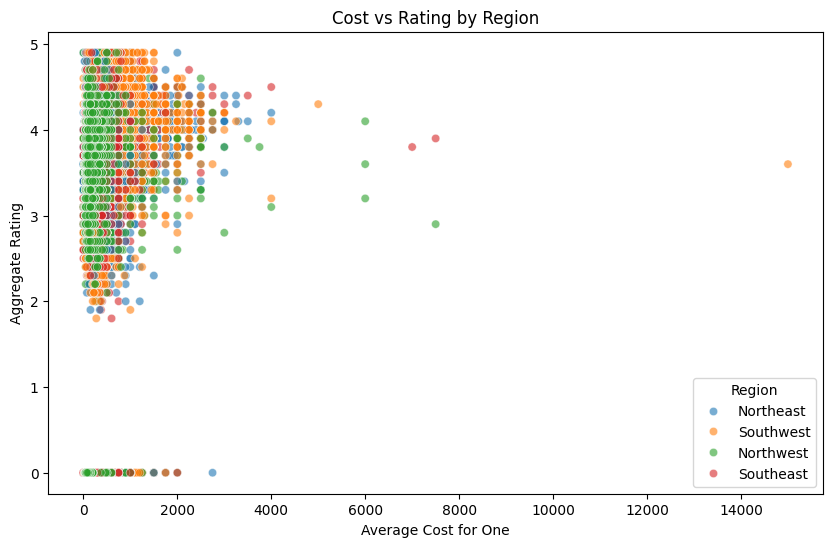

In [54]:
# Cost vs Rating Analysis

plt.figure(figsize=(10,6))
sns.scatterplot(data=filtered_food_dely_copy, x='average_cost_for_one', y='aggregate_rating', hue='region', alpha=0.6)
plt.title('Cost vs Rating by Region')
plt.xlabel('Average Cost for One')
plt.ylabel('Aggregate Rating')
plt.legend(title='Region', loc='lower right')
plt.show()

## The above correlation shows that higher the cost does not mean higher rating. 
### There is an outlier for Southwest region above in which the average cost for one person is more than 14,000 yet the rating is between 3 & 4.

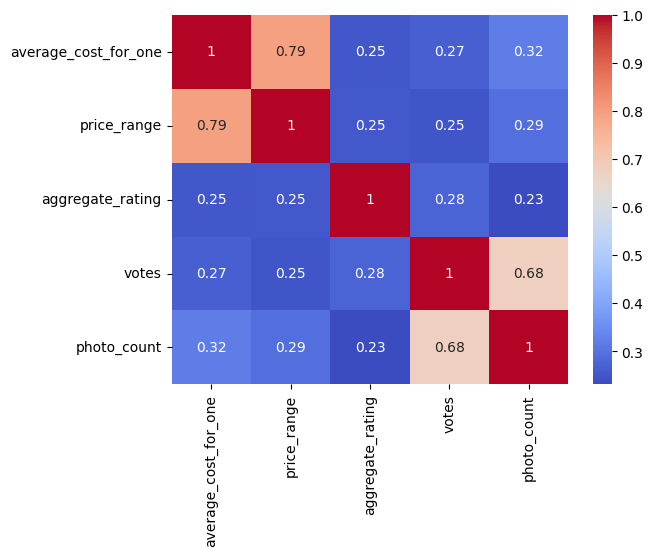

In [55]:
# Heatmap for understanding the correlation between numerical variables with each other.

corr_matrix = filtered_food_dely_copy[['average_cost_for_one', 'price_range', 'aggregate_rating', 'votes', 'photo_count']].corr()
sns.heatmap(corr_matrix, annot=True, cmap='coolwarm')
plt.show()

## There is a positive correlation between average_cost for one and price_range, as the average price for one person increases the price range of the restaurant also increases - which means the costlier it gets.

## There is another positive correlation between votes and photo_count. The higher the photos of the restaurant, the higher amount of votes or vice-e-versa.

### All the other relations seem to be normal.

## Another correlation is - it is not necessary that costlier the restaurant gets - the rating does not increase as well. Higher price does not necessarily mean higher rating

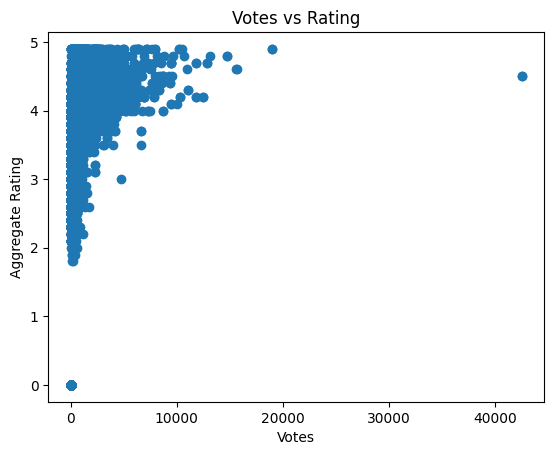

In [56]:
# Another correlation - are higher ratings means popular restaurants? We define popular restaurants as those having higher votes.

plt.figure()
plt.scatter(filtered_food_dely_copy['votes'], filtered_food_dely_copy['aggregate_rating'])
plt.xlabel("Votes")
plt.ylabel("Aggregate Rating")
plt.title("Votes vs Rating")
plt.show()

## The number of votes are looking as directly proportional to ratings. Meaning higher rating is popular restaurant(restaurant with more votes).

<Figure size 640x480 with 0 Axes>

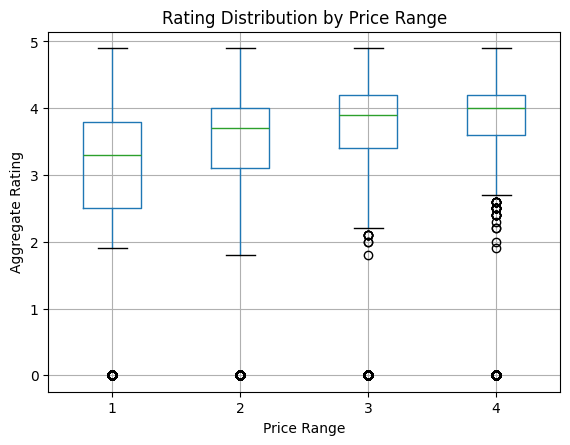

In [57]:
# Another correlation - boxplot to understand the distribution of ratings across different price ranges.

plt.figure()
filtered_food_dely_copy.boxplot(column='aggregate_rating', by='price_range')
plt.title("Rating Distribution by Price Range")
plt.suptitle("")
plt.xlabel("Price Range")
plt.ylabel("Aggregate Rating")
plt.show()

### 1 is the lowest price range and 4 is highest price range

## As per the boxplot, we can understand that the ratings are widely distributed for lower price point 1 - between 2.5 - 3.8
## For price range 2, the ratings are distributed between 3.1/3.2 - 4
## For price range 3, the ratings are distributed between 3.5 - 4.2 something.
## For price range 4(costliest bracket), the ratings are distributed between 3.6/3.7 - 4.2

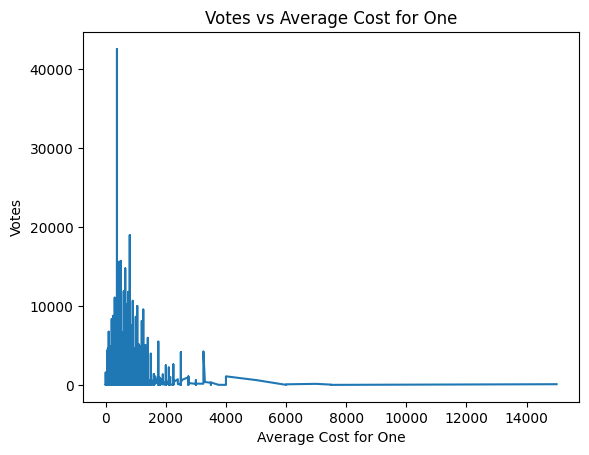

In [58]:
# This is a line graph to understand the relationship between average cost for one and votes.

sorted_filtered_food_dely_copy = filtered_food_dely_copy.sort_values('average_cost_for_one')

plt.figure()
plt.plot(sorted_filtered_food_dely_copy['average_cost_for_one'], sorted_filtered_food_dely_copy['votes'])
plt.xlabel("Average Cost for One")
plt.ylabel("Votes")
plt.title("Votes vs Average Cost for One")
plt.show()

## From the above graph it can be noted that the lower the cost for one person, more number of votes.
## Restaurants which are lower cost, they get higher amount of votes.
## Engagement of people for giving votes decreases as the price increases fro one person on average.

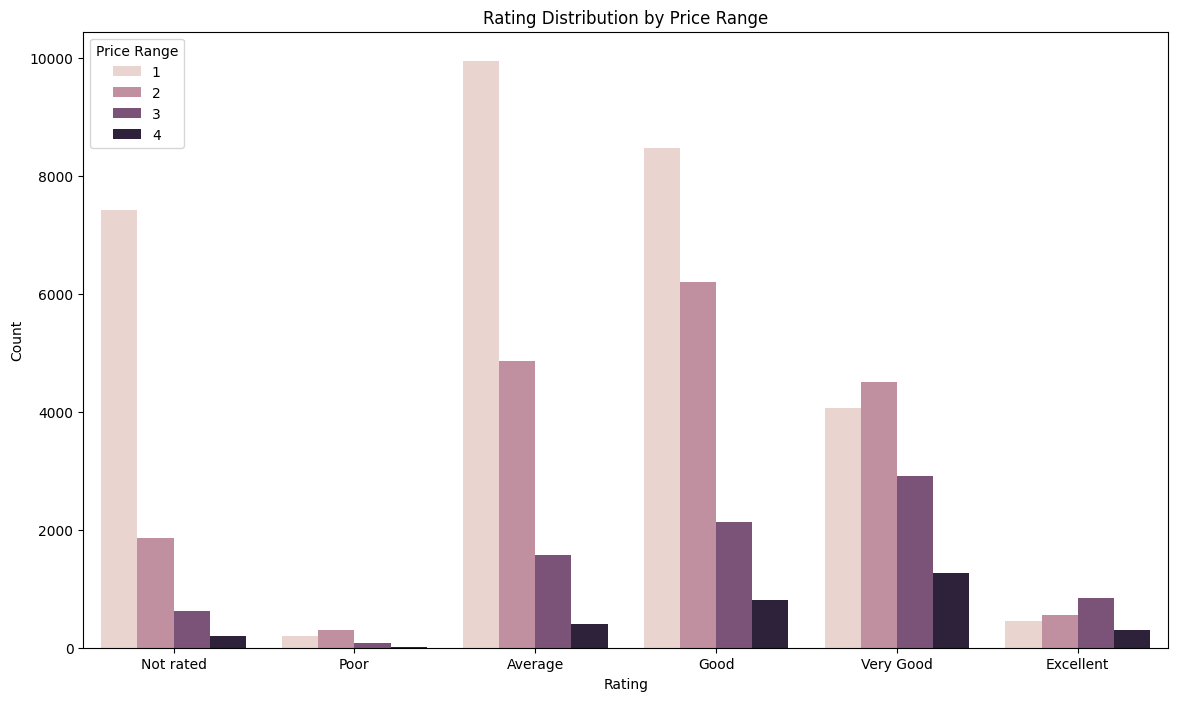

In [59]:
## Rating_text is also another column which can shine light on which establishments were rated according to their price range(from 1 to 4) using countplot.

rating_order = ['Not rated', 'Poor', 'Average', 'Good', 'Very Good', 'Excellent']

plt.figure(figsize=(14, 8))
sns.countplot(data=filtered_food_dely_copy, x='rating_text', hue='price_range', order=rating_order)
plt.title('Rating Distribution by Price Range')
plt.xlabel('Rating')
plt.ylabel('Count')
plt.legend(title='Price Range', loc='upper left')

## From the above plot, we can deduce the following:

### Not Rated restaurants - price range is widely distributed in which the price range 1(lowest price range) is the most restaurants which are not rated. There is a small portion of restaurant rated Excellent for price range 4.

### Poor Rated restaurants - Price range is not as much widely distributed like Not rated restaurants.

### Very Good - It seems to be odd one out and goes outside trend - for price range 2 restaurants got most ratings of Very good.

### Excellent - It seems to outside trend, price range 3 restaurants got the most Excellent ratings.

This count plot shows the ratings are not dependent on price range because even for Excellent rating, price range 4 has the lowest number of restaurants. Whereas for Poor rating, price range 2 has most number of restaurants.
It is neither directly nor indirectly propertional.

Text(120.72222222222221, 0.5, 'Region')

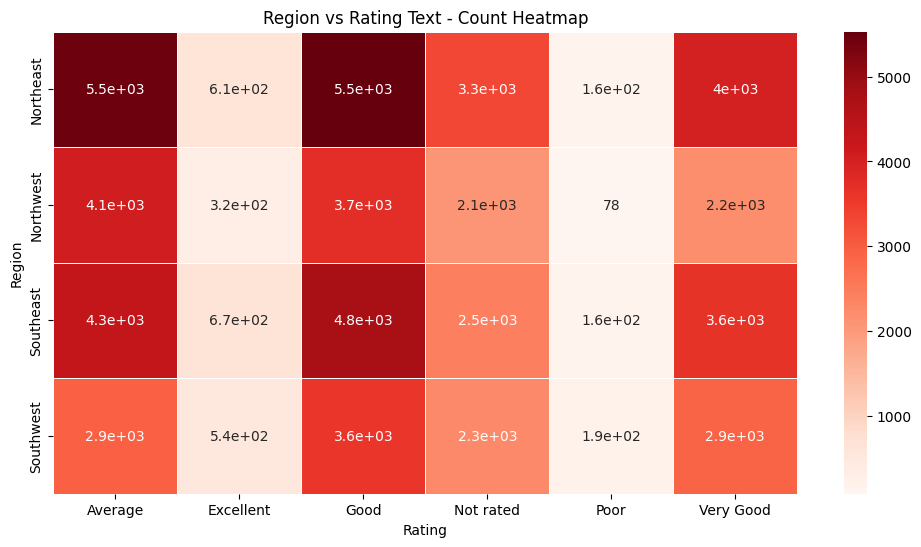

In [60]:
# Heat map of ratings across different regions to see if certain areas have better-rated establishments.

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

region_rating_counts = pd.crosstab(filtered_food_dely_copy['region'], filtered_food_dely_copy['rating_text'])

plt.figure(figsize=(12, 6))
sns.heatmap(region_rating_counts, annot=True, cmap='Reds', linewidths=0.5)
plt.title('Region vs Rating Text - Count Heatmap')
plt.xlabel('Rating')
plt.ylabel('Region')

In [61]:
filtered_food_dely_copy['region'].value_counts()

region
Northeast    19087
Southeast    16037
Northwest    12486
Southwest    12402
Name: count, dtype: int64

## Based on the above heatmap graph, we can learn that:

### Northeast has the most restaurants which are rated and is consistent with the data we have.
### Southeast comes next with more restaurants which are in the region and also has the more ratings.. Data is consistent.

### We can deduce that any region with more restaurants has more rated restaurants.

<Figure size 2000x1000 with 0 Axes>

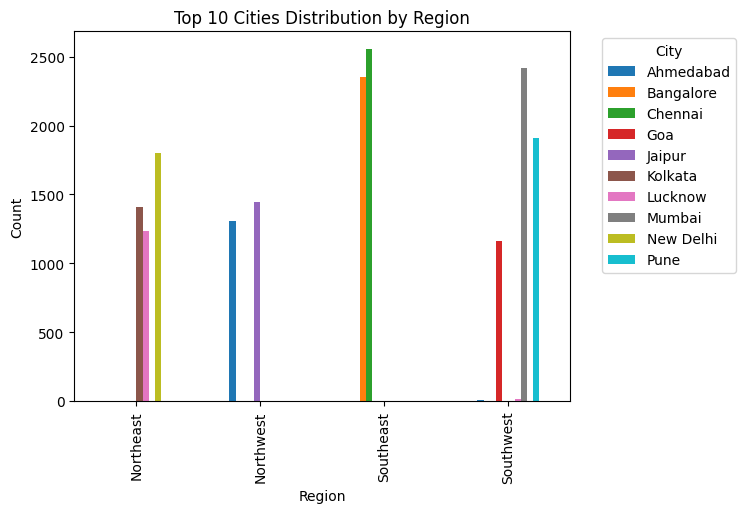

In [62]:
# Top cities distribution by region analysis

top_cities = filtered_food_dely_copy['city'].value_counts().head(10).index
city_region = filtered_food_dely_copy[filtered_food_dely_copy['city'].isin(top_cities)].groupby(['region', 'city']).size().unstack(fill_value=0)

plt.figure(figsize=(20,10))
city_region.plot(kind='bar')
plt.title('Top 10 Cities Distribution by Region')
plt.xlabel('Region')
plt.ylabel('Count')
plt.legend(title='City', loc='upper left', bbox_to_anchor=(1.05, 1))

## From the above graph we can understand the following:

### This is the graph which shows the top cities based on the counts distributed as epr different regions in our data frame.

### There are 3 top cities in the North East region - Lucknow, New Delhi and kolkata
### There are 2 top cities in the North West region - Ahmedabad, Jaipur
### There are 2 top cities in the South East region - Bangalore, Chennai
### There are 3 top cities in the South West region - Goa, Mumbai, Pune

Text(0.5, 1.0, 'Delivery Availability Distribution')

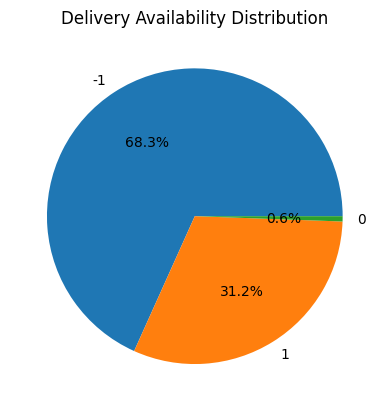

In [63]:
# Delivery analysis
delivery_counts = filtered_food_dely_copy['delivery'].value_counts()
plt.figure()
plt.pie(delivery_counts, labels=delivery_counts.index, autopct='%1.1f%%')
plt.title('Delivery Availability Distribution')

In [64]:
filtered_food_dely_copy['delivery'].value_counts()

delivery
-1    40971
 1    18698
 0      343
Name: count, dtype: int64

## From the above Pie chart we can figure out following which is consistent with the data as well:

### Most of the restaurants do not support delivery so it can be good business insight for people who want to know if delivery can help in sales or not. Or any other business related decisions.

<Figure size 640x480 with 0 Axes>

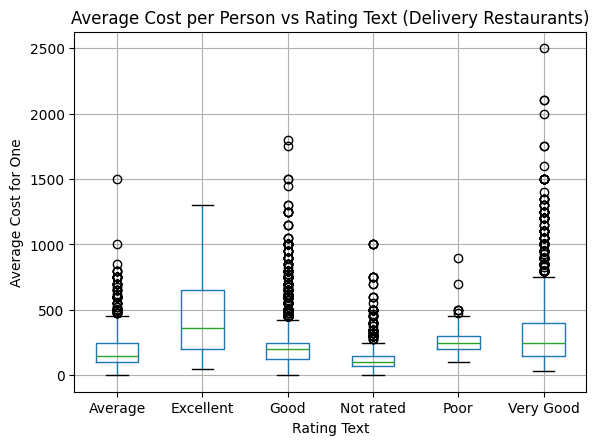

In [65]:
# We can also check how average cost for one varies with rating text for restaurants that offer delivery.

delivery_filtered_food_dely_copy = filtered_food_dely_copy[filtered_food_dely_copy['delivery'] == 1]

plt.figure()
delivery_filtered_food_dely_copy.boxplot(column='average_cost_for_one', by='rating_text')
plt.title("Average Cost per Person vs Rating Text (Delivery Restaurants)")
plt.suptitle("")
plt.xlabel("Rating Text")
plt.ylabel("Average Cost for One")
plt.show()

## From the above graph we can understand the following:

### Excellent rated restaurants have higher median prices.
### Lower rated restaurants generally have wider variety in prices.

### The black dots are outliers.

- Sometimes a restaurant who's rated average - the cost for those restaurants would normally fall between 0 and 500. But an outlier would be the dots over the average price range.
- Means usually the restaurants who do delivery - rated average - outliers would be the prices outside the range. That's why there are dots over the box.
- Applies same for all the other ratings.

## Insights that can drive smarter food decisions based on above data and correlations.
 ### For current business owners - 
- Encourage users to upload more instagrammable photos. Create a photo booth, provide discounts to upload reviews with photos etc as we saw more photo uploads, more votes. More votes -> More orders which leads to more business.
- Start delivery, there are less restaurants which offer delivery - gives first movers advantage.
- Adding more cuisines will add to business.
- Keeping price economical will generate more traffic of orders.
 ### For new business owners -
- For new business owners - the safe bet is to serve North Indian food.
- To stand out, considering a "Fusion" model—combine a high-volume base (like North Indian) with a high-rated specialty (like Continental) to capture both traffic and high reviews.
- The Northeast region has the highest concentration of cuisine variety and restaurant activity.
- The Southwest has the most unique cities (87) but lower cuisine density than the Northeast.
- The data shows that "Price Range 3" restaurants often have a better "Rating-to-Cost" ratio than Price Range 4. Range 3 establishes a "premium" feel without the extreme expectations (and potential for harsh reviews) that come with the most expensive tier. 
- Most restauramts are in Price range 1 or 2 - so avoid as well to not be in mass category.

# ==========================================================================================================================
# ==========================================================================================================================

#                                                          EXTRA INSIGHTS

# ==========================================================================================================================
# ==========================================================================================================================

In [66]:
# Checking the number of restaurants in each city

city_data = pd.Series(filtered_food_dely_copy['city'])
city_counts = city_data.value_counts()
city_counts

city
Chennai          2560
Mumbai           2417
Bangalore        2355
Pune             1907
New Delhi        1804
                 ... 
Udupi              61
Howrah             50
Neemrana           26
Greater Noida      22
Nayagaon           15
Name: count, Length: 98, dtype: int64

In [67]:
# Taking the city_counts and converting it into a dataframe, resetting index because currently the city name is index and sorting by counts descending.

city_res_df = city_counts.to_frame(name='counts').reset_index().sort_values(by='counts', ascending=False)

In [68]:
pd.options.display.max_rows = 100
city_res_df

,city,counts
0,Chennai,2560
1,Mumbai,2417
2,Bangalore,2355
3,Pune,1907
4,New Delhi,1804
5,Jaipur,1451
6,Kolkata,1412
7,Ahmedabad,1308
8,Lucknow,1250
9,Goa,1164


### In this dataframe, we can see all the different 98 cities in the database arranged in descending order based on the number of restaurants each city has.

In [69]:
# To find out the different cuisines offered by the restaurants, we can split the 'cuisines' column which contains multiple cuisines separated by commas.

df_cuisine = filtered_food_dely_copy["cuisines"].str.split(',', expand=True)
df_cuisine.head()


,0,1,2,3,4,5,6,7
0,North Indian,South Indian,Mithai,Street Food,Desserts,None,None,None
1,North Indian,Mughlai,Rolls,Chinese,Fast Food,Street Food,None,None
2,Fast Food,Mithai,None,None,None,None,None,None
3,Desserts,Bakery,Fast Food,South Indian,None,None,None,None
4,North Indian,Continental,Italian,None,None,None,None,None


## Ideas

- There can be a correlation that we can establish between cities in each region and the top cuisines in those cities as per region by creating a heatmap.
- There can also be a correlation between the number of cuisines available in each region.
- There can also be a correlation among the cities in same region having different number of cuisines.
- A stacked bar for each region and the stacking depends on the top 10 cuisines.


# THE END